# 📊 Unemployment Analysis with Python

### CodeAlpha Data Science Internship

## Project Objective

The objective of this project is to analyze unemployment rate data using
Python.

The project focuses on:

- Understanding unemployment trends over time
- Cleaning and exploring the dataset
- Visualizing unemployment rates
- Investigating the impact of COVID-19 on unemployment
- Identifying important patterns and trends
- Deriving insights that may help understand economic and social conditions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv("Unemployment in India.csv")

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 768
Number of columns: 7


In [4]:
print(df.columns)

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [5]:
df.columns = df.columns.str.strip()

print(df.columns)

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [6]:
print(df.isnull().sum())

Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


In [7]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

print(df["Date"].head())

0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[ns]


In [8]:
print(df.dtypes)

Region                                             object
Date                                       datetime64[ns]
Frequency                                          object
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               object
dtype: object


In [9]:
print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())

Start Date: 2019-05-31 00:00:00
End Date: 2020-06-30 00:00:00


In [10]:
print("Number of Regions:", df["Region"].nunique())

print("\nRegions:")
print(df["Region"].unique())

print("\nAreas:")
print(df["Area"].unique())

print("\nFrequency:")
print(df["Frequency"].unique())

Number of Regions: 28

Regions:
['Andhra Pradesh' 'Assam' 'Bihar' 'Chhattisgarh' 'Delhi' 'Goa' 'Gujarat'
 'Haryana' 'Himachal Pradesh' 'Jammu & Kashmir' 'Jharkhand' 'Karnataka'
 'Kerala' 'Madhya Pradesh' 'Maharashtra' 'Meghalaya' 'Odisha' 'Puducherry'
 'Punjab' 'Rajasthan' 'Sikkim' 'Tamil Nadu' 'Telangana' 'Tripura'
 'Uttar Pradesh' 'Uttarakhand' 'West Bengal' nan 'Chandigarh']

Areas:
['Rural' nan 'Urban']

Frequency:
[' Monthly' nan 'Monthly']


In [11]:
df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378496,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [12]:
average_unemployment = df["Estimated Unemployment Rate (%)"].mean()

print("Average Unemployment Rate:", round(average_unemployment, 2), "%")

Average Unemployment Rate: 11.79 %


In [13]:
highest_unemployment = df["Estimated Unemployment Rate (%)"].max()

print("Highest Unemployment Rate:", highest_unemployment, "%")

Highest Unemployment Rate: 76.74 %


In [14]:
lowest_unemployment = df["Estimated Unemployment Rate (%)"].min()

print("Lowest Unemployment Rate:", lowest_unemployment, "%")

Lowest Unemployment Rate: 0.0 %


In [15]:
monthly_unemployment = df.groupby("Date")["Estimated Unemployment Rate (%)"].mean()

monthly_unemployment

Date
2019-05-31     8.874259
2019-06-30     9.303333
2019-07-31     9.033889
2019-08-31     9.637925
2019-09-30     9.051731
2019-10-31     9.900909
2019-11-30     9.868364
2019-12-31     9.497358
2020-01-31     9.950755
2020-02-29     9.964717
2020-03-31    10.700577
2020-04-30    23.641569
2020-05-31    24.875294
2020-06-30    11.903600
Name: Estimated Unemployment Rate (%), dtype: float64

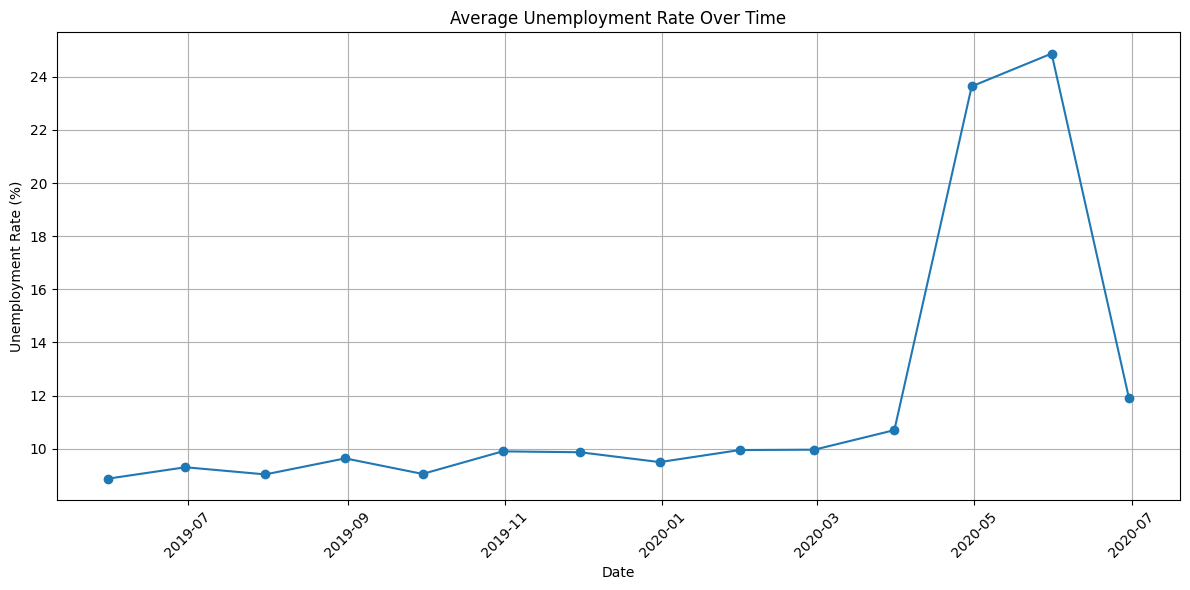

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o"
)

plt.title("Average Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
highest_month = monthly_unemployment.idxmax()
highest_value = monthly_unemployment.max()

print("Month with highest average unemployment:", highest_month)
print("Unemployment Rate:", round(highest_value, 2), "%")

Month with highest average unemployment: 2020-05-31 00:00:00
Unemployment Rate: 24.88 %


In [18]:
area_unemployment = df.groupby("Area")["Estimated Unemployment Rate (%)"].mean()

print(area_unemployment)

Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


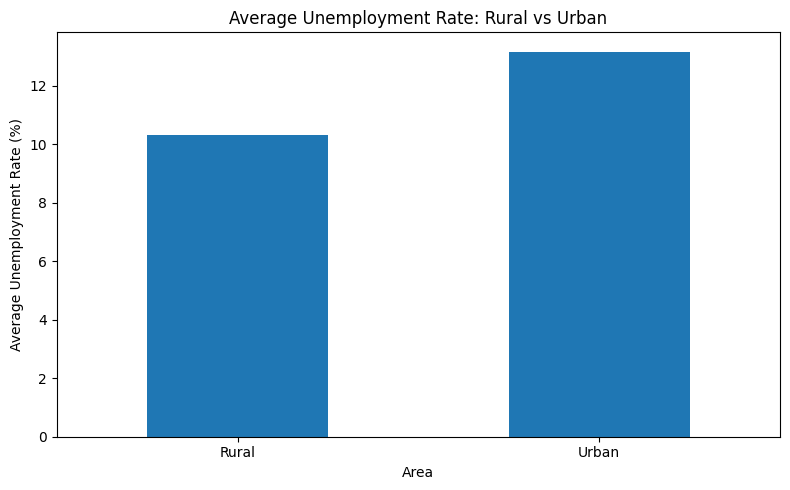

In [19]:
plt.figure(figsize=(8, 5))

area_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [20]:
for area, rate in area_unemployment.items():
    print(area, ":", round(rate, 2), "%")

Rural : 10.32 %
Urban : 13.17 %


In [21]:
region_unemployment = df.groupby("Region")["Estimated Unemployment Rate (%)"].mean()

print(region_unemployment.sort_values(ascending=False))

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


In [22]:
highest_region = region_unemployment.idxmax()
highest_region_rate = region_unemployment.max()

lowest_region = region_unemployment.idxmin()
lowest_region_rate = region_unemployment.min()

print("Highest average unemployment:")
print(highest_region, ":", round(highest_region_rate, 2), "%")

print("\nLowest average unemployment:")
print(lowest_region, ":", round(lowest_region_rate, 2), "%")

Highest average unemployment:
Tripura : 28.35 %

Lowest average unemployment:
Meghalaya : 4.8 %


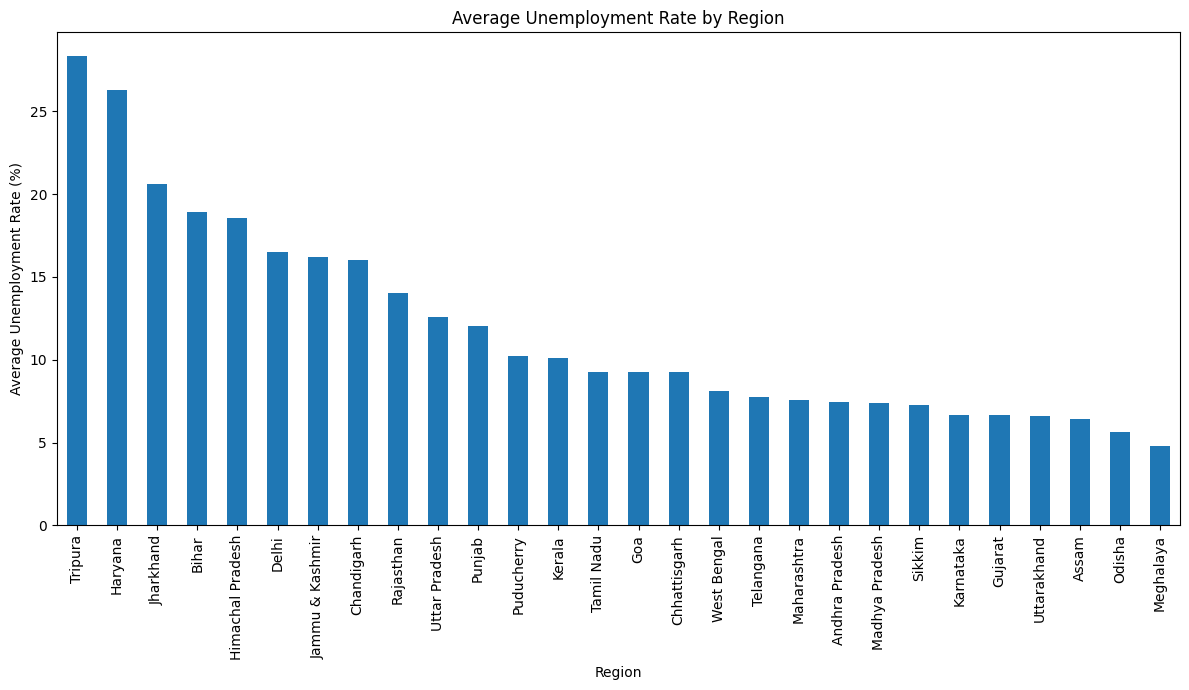

In [23]:
plt.figure(figsize=(12, 7))

region_unemployment.sort_values(ascending=False).plot(kind="bar")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [24]:
df["Year"] = df["Date"].dt.year

yearly_unemployment = df.groupby("Year")[
    "Estimated Unemployment Rate (%)"
].mean()

print(yearly_unemployment)

Year
2019.0     9.399047
2020.0    15.101581
Name: Estimated Unemployment Rate (%), dtype: float64


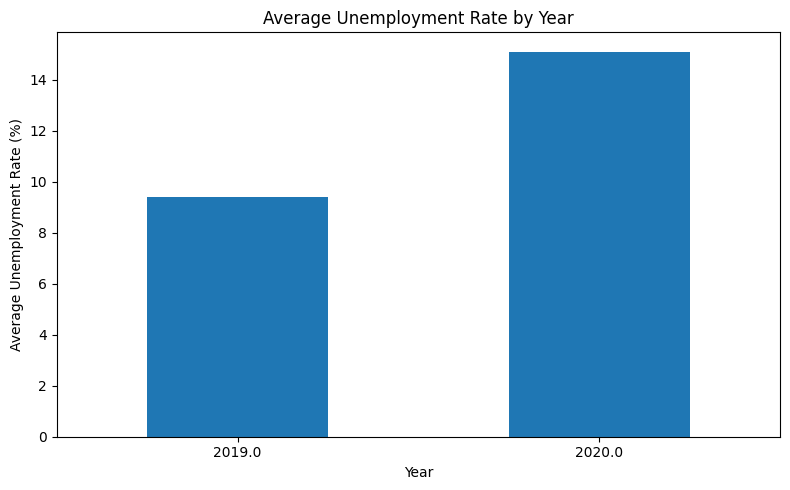

In [25]:
plt.figure(figsize=(8, 5))

yearly_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate by Year")
plt.xlabel("Year")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [26]:
for year, rate in yearly_unemployment.items():
    print(year, ":", round(rate, 2), "%")

2019.0 : 9.4 %
2020.0 : 15.1 %


In [27]:
monthly_change = monthly_unemployment.diff()

print(monthly_change)

Date
2019-05-31          NaN
2019-06-30     0.429074
2019-07-31    -0.269444
2019-08-31     0.604036
2019-09-30    -0.586194
2019-10-31     0.849178
2019-11-30    -0.032545
2019-12-31    -0.371005
2020-01-31     0.453396
2020-02-29     0.013962
2020-03-31     0.735860
2020-04-30    12.940992
2020-05-31     1.233725
2020-06-30   -12.971694
Name: Estimated Unemployment Rate (%), dtype: float64


In [28]:
biggest_increase_date = monthly_change.idxmax()
biggest_increase = monthly_change.max()

print("Biggest increase:", biggest_increase_date)
print("Increase:", round(biggest_increase, 2), "percentage points")

Biggest increase: 2020-04-30 00:00:00
Increase: 12.94 percentage points


In [29]:
biggest_decrease_date = monthly_change.idxmin()
biggest_decrease = monthly_change.min()

print("Biggest decrease:", biggest_decrease_date)
print("Decrease:", round(biggest_decrease, 2), "percentage points")

Biggest decrease: 2020-06-30 00:00:00
Decrease: -12.97 percentage points


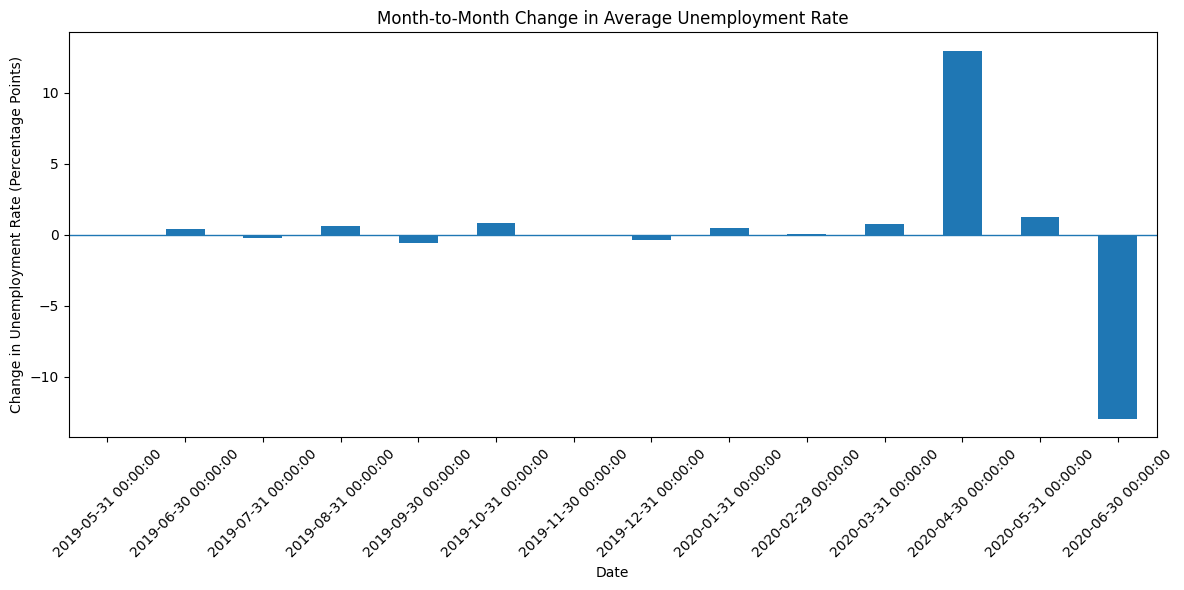

In [30]:
plt.figure(figsize=(12, 6))

monthly_change.plot(kind="bar")

plt.title("Month-to-Month Change in Average Unemployment Rate")
plt.xlabel("Date")
plt.ylabel("Change in Unemployment Rate (Percentage Points)")
plt.xticks(rotation=45)

plt.axhline(0, linewidth=1)

plt.tight_layout()
plt.show()

In [31]:
correlation = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Labour Participation Rate (%)"
    ]
].corr()

print(correlation)

                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                 1.000000   
Estimated Labour Participation Rate (%)                         0.002558   

                                         Estimated Labour Participation Rate (%)  
Estimated Unemployment Rate (%)                                         0.002558  
Estimated Labour Participation Rate (%)                                 1.000000  


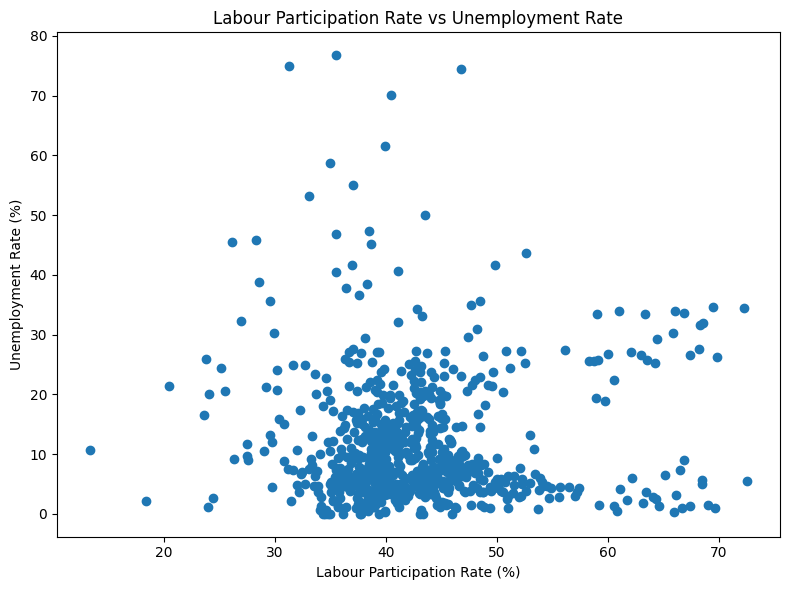

In [32]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Estimated Labour Participation Rate (%)"],
    df["Estimated Unemployment Rate (%)"]
)

plt.title("Labour Participation Rate vs Unemployment Rate")
plt.xlabel("Labour Participation Rate (%)")
plt.ylabel("Unemployment Rate (%)")

plt.tight_layout()
plt.show()

In [33]:
correlation_value = df[
    "Estimated Unemployment Rate (%)"
].corr(
    df["Estimated Labour Participation Rate (%)"]
)

print("Correlation:", round(correlation_value, 3))

Correlation: 0.003


## 📌 Key Findings

Based on the analysis of the unemployment dataset:

1. The dataset contains unemployment information across different regions and areas of India.

2. The average unemployment rate was calculated to understand the overall unemployment situation during the period covered by the dataset.

3. The unemployment rate varied across different regions, showing that unemployment was not equally distributed across India.

4. Rural and urban areas showed differences in their average unemployment rates.

5. The monthly trend showed noticeable changes in unemployment over time.

6. The dataset showed a significant change in unemployment during the period associated with the COVID-19 outbreak.

7. The month-to-month analysis identified periods where unemployment increased or decreased considerably.

8. The correlation analysis helped examine the relationship between unemployment rate and labour participation rate.

9. Overall, the analysis shows that unemployment changed considerably across time, regions, and areas.

## 📝 Conclusion

This project analyzed unemployment data from India using Python.

The dataset was cleaned and explored using Pandas, while Matplotlib and Seaborn were used to create visualizations.

The analysis examined:

- Overall unemployment rate
- Unemployment trends over time
- Rural vs Urban unemployment
- Regional unemployment differences
- Changes during the COVID-19 period
- Month-to-month unemployment changes
- Relationship between unemployment and labour participation rate

The analysis shows that unemployment varied significantly across different regions and time periods. The COVID-19 period was associated with a noticeable change in unemployment levels.

Data analysis and visualization can therefore help identify important unemployment patterns and provide a better understanding of economic conditions.

## 🎯 Project Summary

**Tools Used:**
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

**Main Techniques:**
- Data Cleaning
- Exploratory Data Analysis (EDA)
- Grouping and Aggregation
- Statistical Analysis
- Data Visualization
- Correlation Analysis

**Project Type:** Data Analysis / Exploratory Data Analysis